# AS1 PPO Training, Evaluation, and Report Evidence

This notebook is the experiment controller for the AS1 Godot 2D Platform Collector. Python launches the Godot project through `AS1GodotEnv`, exchanges JSON reset/step messages over local WebSocket port `8765`, trains PPO policies sequentially, evaluates saved policies, and exports report-ready CSV files and figures.

### Execution order and purpose

1. **Set up reproducibility and paths** so every run uses known software, seeds, folders, and queue controls.
2. **Validate the Gymnasium–Godot boundary** before spending time on training.
3. **Measure a random-agent control** to establish the untrained performance floor.
4. **Resolve seven controlled PPO configurations** from one baseline plus one-parameter alternatives.
5. **Train sequentially** because all environments share WebSocket port `8765`.
6. **Screen checkpoints** and retain the strongest checkpoint for each configuration.
7. **Evaluate deterministic and stochastic policies** with a common episode budget.
8. **Generate tables and plots** for comparison, diagnosis, and the assignment report.
9. **Repeat training across additional seeds** to estimate sensitivity to initialization.

When `SKIP_COMPLETED_MODELS` is enabled, existing final model files are reused. This supports recovery after an interrupted long run, but those files must belong to the same observation space, reward design, and experiment version.


## 1. Environment and reinforcement-learning formulation

The environment logic is implemented across `main.gd`, `player.gd`, `apple.gd`, `snail.gd`, and `websocket_bridge.gd`; `as1_env.py` exposes that game as a Gymnasium environment for Stable-Baselines3.

### Observation space: 12 normalized values

| Index | Observation | Purpose |
|---:|---|---|
| 0–1 | Player x/y position | Locates the agent within the level. |
| 2–3 | Horizontal/vertical velocity | Represents current motion and jump phase. |
| 4 | On-floor flag | Indicates whether a jump can begin. |
| 5 | Touching-wall flag | Helps distinguish blocked movement. |
| 6 | Horizontal wall normal | Identifies which side is obstructed. |
| 7–8 | Relative x/y position of the active navigation target | Directs the policy toward the next reachable objective. |
| 9–10 | Relative x/y position of the nearest active snail | Supports enemy avoidance. |
| 11 | Fraction of apples remaining | Represents task progress. |

The active navigation target is normally the nearest apple. After the lower apple is collected, `main.gd` temporarily exposes a central-platform approach waypoint so both the observation and distance shaping describe a reachable route around the wall.

### Discrete action space

| Value | Action | Purpose |
|---:|---|---|
| 0 | Do nothing | Allows waiting or preserving a trajectory. |
| 1 | Move left | Horizontal control. |
| 2 | Move right | Horizontal control. |
| 3 | Jump | Vertical control without horizontal input. |
| 4 | Move left and jump | Combined platforming action. |
| 5 | Move right and jump | Combined platforming action. |

### Reward and termination design

| Event | Reward | Purpose |
|---|---:|---|
| Each decision step | −0.01 | Discourages unnecessarily long episodes. |
| Reach the upper-apple waypoint once | +4 | Rewards the required detour. |
| Collect an apple | +5 | Rewards partial task progress. |
| Collect all apples | +20 | Rewards successful completion and terminates the episode. |
| Hit an enemy | −10 | Penalizes unsafe movement and terminates the episode. |
| Fall below the level | −10 | Penalizes falling and terminates the episode. |
| Reach 1,000 decisions | −8 | Ends the episode as a Gymnasium truncation. |
| Move toward/away from the active target | Clipped to [−0.1, +0.1] | Supplies dense progress feedback without overwhelming event rewards. |

`websocket_bridge.gd` pauses the scene between requests. One Python action is held for four Godot physics ticks, so movement, collisions, rewards, and the returned transition stay synchronized.


## 2. Setup and reproducibility

The next cell imports the numerical, plotting, Gymnasium, WebSocket, and PPO libraries used throughout the notebook. It seeds Python, NumPy, PyTorch, Stable-Baselines3, and later the environment action space with `SEED = 123`. It also prints package, platform, and accelerator information so results can be reproduced and the report can record the actual execution environment.


In [1]:
import platform
import random
import shutil
import sys
import time
from pathlib import Path

import gymnasium
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import stable_baselines3
import torch
import websockets
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.utils import set_random_seed

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_random_seed(SEED)

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Gymnasium:", gymnasium.__version__)
print("Stable-Baselines3:", stable_baselines3.__version__)
print("PyTorch:", torch.__version__)
print("WebSockets:", websockets.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Apple MPS available:", torch.backends.mps.is_available())

Python executable: /Users/booxuan/miniconda3/envs/rl-ppo/bin/python
Python version: 3.11.15 (main, Jun 11 2026, 15:14:57) [Clang 20.1.8 ]
Platform: macOS-26.6.1-arm64-arm-64bit
Gymnasium: 1.3.0
Stable-Baselines3: 2.9.0
PyTorch: 2.13.0
WebSockets: 17.0.1
NumPy: 2.4.6
Pandas: 3.0.5
Matplotlib: 3.11.1
Apple MPS available: True


### 2.1 Project paths and execution controls

The next cell searches upward from the current working directory for `project.godot`, creates canonical `results/` and `models/` folders, and adds `agent/` to Python's import path before importing `AS1GodotEnv`.

The control variables separate quick checks from expensive work:

- `HEADLESS` controls rendering; headless mode is intended for faster training.
- `TRAIN_EXPERIMENTS` enables or disables the main training queue.
- `SKIP_COMPLETED_MODELS` supports resuming from existing final model files.
- `SMOKE_TEST_TIMESTEPS` and `TARGET_TOTAL_TIMESTEPS` define the short preflight stage and full per-model budget.
- Episode counts define random, checkpoint-screening, and final-evaluation sample sizes.
- `EXPERIMENT_NAMES_TO_RUN` selects all seven active configurations.

`CONFIG_DIRECTORY` is still assigned for the obsolete JSON-loader block later in the notebook, but active configurations are defined directly in code and do not use that directory.


In [2]:
# Locate the repository from the notebook directory or any parent directory.
search_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
AS1_DIRECTORY = next(
    (
        location
        for location in search_locations
        if (location / "project.godot").exists()
    ),
    None,
)
if AS1_DIRECTORY is None:
    raise FileNotFoundError(
        "Could not locate the AS1 Godot project (project.godot) from the current directory"
    )

AGENT_DIRECTORY = AS1_DIRECTORY / "agent"
CONFIG_DIRECTORY = AGENT_DIRECTORY / "ppo_configs"
# Keep corrected 12-observation models versioned so old pilot models cannot
# be loaded accidentally by SKIP_COMPLETED_MODELS. Results are canonical.
# EXPERIMENT_VERSION = "claude_edited"
RESULTS_DIRECTORY = AS1_DIRECTORY / "results"
MODELS_DIRECTORY = AS1_DIRECTORY / "models"  # / EXPERIMENT_VERSION
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
MODELS_DIRECTORY.mkdir(parents=True, exist_ok=True)

if str(AGENT_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(AGENT_DIRECTORY))

from as1_env import AS1GodotEnv

# Queue controls. Review these values before starting a long run.
#
# HEADLESS = True skips rendering entirely and, combined with the
# "--fixed-fps" flag already set inside as1_env.py, lets Godot's physics run
# much faster than real time. Only switch this to False temporarily when you
# want to visually watch the agent play (e.g. for a report screenshot/video).
HEADLESS = True
TRAIN_EXPERIMENTS = True
# Set to True only if you already have completed models for some configs
# (e.g. from an earlier partial run) and want to skip retraining them.
SKIP_COMPLETED_MODELS = False
SMOKE_TEST_TIMESTEPS = 5_000
TARGET_TOTAL_TIMESTEPS = 200_000
RANDOM_BASELINE_EPISODES = 50
# Run every configuration found in ppo_configs (currently: baseline, low_lr,
# high_entropy, low_clip). See the JSON files in CONFIG_DIRECTORY.
EXPERIMENT_NAMES_TO_RUN = {
    "baseline",
    "low_lr",
    "high_entropy",
    "very_high_entropy",
    "low_clip",
    "high_gamma",
    "larger_rollout",
}
CHECKPOINT_FREQUENCY = 10_000
CHECKPOINT_SCREEN_EPISODES = 5
FINAL_EVALUATION_EPISODES = 50

print("AS1 project directory:", AS1_DIRECTORY)
print("Configuration directory:", CONFIG_DIRECTORY)
print("Results directory:", RESULTS_DIRECTORY)
print("Models directory:", MODELS_DIRECTORY)
print("AS1GodotEnv imported successfully")

AS1 project directory: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1
Configuration directory: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/agent/ppo_configs
Results directory: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results
Models directory: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/models
AS1GodotEnv imported successfully


## 3. Reusable evaluation and plotting functions

The next cell centralizes operations that must remain consistent across policies:

- `run_episodes` executes complete random or PPO episodes, records episode metrics, and optionally retains every visited player position.
- `summarize_results` converts episode records into report metrics: mean reward, reward variability, episode length, apples, and completion rate.
- `save_figure` applies a consistent layout, saves a 300-DPI image under `results/`, and displays it in the notebook.

Reusing these functions prevents the random baseline and trained policies from being measured with different logic.


In [3]:
def run_episodes(
    env,
    episodes,
    *,
    model=None,
    seed=SEED,
    deterministic=True,
):
    """Evaluate a random policy (model=None) or a supplied model for a fixed
    number of complete episodes.

    Returns two DataFrames:
    - results_df: one row per episode (reward, steps, terminal reason, etc.)
    - positions_df: one row per environment step with the player's (x, y)
      position, tagged by episode number. Used for trajectory/heatmap plots.
    """
    records = []
    positions = []
    observation, info = env.reset(seed=seed)

    for episode in range(1, episodes + 1):
        episode_reward = 0.0
        episode_steps = 0
        terminated = False
        truncated = False

        # Record the player's starting position for this episode.
        positions.append(
            {"episode": episode, "x": info.get("player_x"), "y": info.get("player_y")}
        )

        while not (terminated or truncated):
            if model is None:
                action = env.action_space.sample()
            else:
                action, _state = model.predict(
                    observation,
                    deterministic=deterministic,
                )

            observation, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            episode_steps += 1

            # Record the position after every step, not just at episode end,
            # so the trajectory/heatmap plot shows the whole path taken.
            positions.append(
                {"episode": episode, "x": info["player_x"], "y": info["player_y"]}
            )

        records.append(
            {
                "episode": episode,
                "reward": episode_reward,
                "steps": episode_steps,
                "reason": info.get("reason", "unknown"),
                "apples_collected": info.get("apples_collected", 0),
                "completed": info.get("reason") == "success",
            }
        )

        if episode < episodes:
            observation, info = env.reset()

    return pd.DataFrame(records), pd.DataFrame(positions)


def summarize_results(results_df):
    # Return report-ready aggregate metrics for one policy.
    return {
        "episodes": len(results_df),
        "mean_reward": results_df["reward"].mean(),
        "reward_std": results_df["reward"].std(),
        "mean_steps": results_df["steps"].mean(),
        "mean_apples": results_df["apples_collected"].mean(),
        "completion_rate": results_df["completed"].mean(),
    }


def save_figure(filename):
    # Save the currently active matplotlib figure at report quality (300 DPI)
    # into RESULTS_DIRECTORY, then display it inline. Every plotting cell in
    # this notebook calls this at the end instead of plt.show() directly, so
    # every figure used as report evidence is also saved to disk automatically.
    plt.tight_layout()
    plt.savefig(RESULTS_DIRECTORY / filename, dpi=300, bbox_inches="tight")
    plt.show()


## 4. Validate the Gymnasium–Godot interface

This preflight constructs one Godot environment, runs Stable-Baselines3's `check_env`, and closes the process even if validation fails. Its purpose is to detect invalid observation shapes, ranges, action handling, reset behavior, or Gymnasium return types before long PPO training begins. The separate `test_environment.py` performs deeper synchronization and terminal-state checks.


In [4]:
validation_env = AS1GodotEnv(headless=HEADLESS)
try:
    check_env(validation_env, warn=True)
    print("Gymnasium environment validation passed")
finally:
    validation_env.close()

Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Gymnasium environment validation passed


## 5. Random-agent baseline

The random policy is the control condition. It samples from the same six-action space for 50 complete episodes, saves the per-episode evidence to `random_agent_results.csv`, and computes the same summary metrics later used for PPO. A useful trained policy should generally improve task-specific measures—especially apples and completion rate—not merely reward.


In [5]:
random_env = AS1GodotEnv(headless=HEADLESS)
random_env.action_space.seed(SEED)
try:
    # run_episodes returns (per-episode results, per-step positions);
    # the random baseline doesn't need a trajectory plot, so positions
    # are discarded here with "_".
    random_results_df, _ = run_episodes(
        random_env, RANDOM_BASELINE_EPISODES, model=None
    )
finally:
    random_env.close()

random_results_df.to_csv(RESULTS_DIRECTORY / "random_agent_results.csv", index=False)
random_summary = summarize_results(random_results_df)
display(random_results_df)
pd.Series(random_summary)


Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org



,episode,reward,steps,reason,apples_collected,completed
0,1,-10.538350,39,enemy,0,False
1,2,-12.996260,303,enemy,0,False
2,3,-10.490626,37,enemy,0,False
3,4,-11.649151,149,enemy,0,False
4,5,-11.727884,180,enemy,0,False
5,6,-17.785692,1000,timeout,0,False
6,7,-18.283027,839,enemy,0,False
7,8,-11.020568,86,enemy,0,False
8,9,-15.402988,547,enemy,0,False
9,10,-10.010000,1,enemy,0,False


episodes            50.000000
mean_reward        -12.393777
reward_std           2.328368
mean_steps         250.580000
mean_apples          0.000000
completion_rate      0.000000
dtype: float64

## 6. PPO experiment definitions

The active experiment list contains one baseline and six alternatives. Each alternative changes one PPO setting relative to the baseline, allowing a clearer attribution of performance changes than changing several settings simultaneously. All selected configurations share the environment, seed, training budget, policy type, and evaluation protocol.


### 6.1 Controlled hyperparameter plan

The active cell defines configurations directly in the notebook; it does not read JSON files.

| Configuration | Single change from baseline | Intended question |
|---|---|---|
| Baseline | None | What performance does the reference PPO setup achieve? |
| Lower learning rate | `0.0003 → 0.0001` | Do smaller updates improve stability? |
| Higher exploration | `ent_coef: 0.01 → 0.02` | Does modestly stronger exploration discover better routes? |
| Much higher exploration | `ent_coef: 0.01 → 0.05` | Does aggressive exploration help or disrupt learning? |
| Smaller PPO clip | `clip_range: 0.20 → 0.10` | Do more conservative policy updates improve behavior? |
| Higher discount | `gamma: 0.99 → 0.995` | Does valuing more distant rewards help with the upper-apple route? |
| Larger rollout | `n_steps: 1024 → 2048` | Does collecting more experience per update improve estimates? |

The cell validates required fields, rejects unknown override names and duplicate experiment names, resolves every override against `BASE_PPO_CONFIG`, and exports `experiment_plan.csv`.


In [6]:
BASE_PPO_CONFIG = {
    "learning_rate": 0.0003,
    "n_steps": 1024,
    "batch_size": 64,
    "n_epochs": 10,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "clip_range": 0.20,
    "ent_coef": 0.01,
}

# Configurations defined directly in the notebook instead of separate JSON
# files in ppo_configs/. Kept as a list of dicts with the same schema
# (name, label, change, overrides) so every downstream cell works unchanged.
EXPERIMENTS = [
    {
        "name": "baseline",
        "label": "Baseline",
        "change": "Reference configuration",
        "overrides": {},
    },
    {
        "name": "low_lr",
        "label": "Lower learning rate",
        "change": "learning_rate: 0.0003 to 0.0001",
        "overrides": {"learning_rate": 0.0001},
    },
    {
        "name": "high_entropy",
        "label": "Higher exploration",
        "change": "ent_coef: 0.01 to 0.02",
        "overrides": {"ent_coef": 0.02},
    },
    {
        "name": "low_clip",
        "label": "Smaller PPO clip",
        "change": "clip_range: 0.20 to 0.10",
        "overrides": {"clip_range": 0.1},
    },
    {
        "name": "very_high_entropy",
        "label": "Much higher exploration",
        "change": "ent_coef: 0.01 to 0.05",
        "overrides": {"ent_coef": 0.05},
    },
    {
        "name": "high_gamma",
        "label": "More patient (higher discount)",
        "change": "gamma: 0.99 to 0.995",
        "overrides": {"gamma": 0.995},
    },
    {
        "name": "larger_rollout",
        "label": "Larger rollout batch",
        "change": "n_steps: 1024 to 2048",
        "overrides": {"n_steps": 2048},
    },
]

# Same validation your JSON-loading cell did — kept so a typo in overrides
# still fails loudly instead of silently training with the wrong config.
required_fields = {"name", "label", "change", "overrides"}
for experiment in EXPERIMENTS:
    missing_fields = required_fields.difference(experiment)
    if missing_fields:
        raise ValueError(
            f"{experiment.get('name')} is missing fields: {sorted(missing_fields)}"
        )
    unknown_parameters = set(experiment["overrides"]).difference(BASE_PPO_CONFIG)
    if unknown_parameters:
        raise ValueError(
            f"{experiment['name']} contains unknown PPO parameters: {sorted(unknown_parameters)}"
        )

experiment_names = [experiment["name"] for experiment in EXPERIMENTS]
if len(experiment_names) != len(set(experiment_names)):
    raise ValueError("Every PPO configuration must have a unique name")

unknown_run_names = EXPERIMENT_NAMES_TO_RUN.difference(experiment_names)
if unknown_run_names:
    raise ValueError(f"Unknown experiment names requested: {sorted(unknown_run_names)}")
EXPERIMENTS_TO_RUN = [e for e in EXPERIMENTS if e["name"] in EXPERIMENT_NAMES_TO_RUN]

experiment_rows = [
    {
        "queue_position": position,
        "name": e["name"],
        "label": e["label"],
        "controlled_change": e["change"],
        **{**BASE_PPO_CONFIG, **e["overrides"]},
    }
    for position, e in enumerate(EXPERIMENTS_TO_RUN, start=1)
]
experiment_plan_df = pd.DataFrame(experiment_rows)
experiment_plan_df.to_csv(RESULTS_DIRECTORY / "experiment_plan.csv", index=False)
experiment_plan_df

,queue_position,name,label,controlled_change,learning_rate,n_steps,batch_size,n_epochs,gamma,gae_lambda,clip_range,ent_coef
0,1,baseline,Baseline,Reference configuration,0.0003,1024,64,10,0.990,0.95,0.2,0.01
1,2,low_lr,Lower learning rate,learning_rate: 0.0003 to 0.0001,0.0001,1024,64,10,0.990,0.95,0.2,0.01
2,3,high_entropy,Higher exploration,ent_coef: 0.01 to 0.02,0.0003,1024,64,10,0.990,0.95,0.2,0.02
3,4,low_clip,Smaller PPO clip,clip_range: 0.20 to 0.10,0.0003,1024,64,10,0.990,0.95,0.1,0.01
4,5,very_high_entropy,Much higher exploration,ent_coef: 0.01 to 0.05,0.0003,1024,64,10,0.990,0.95,0.2,0.05
5,6,high_gamma,More patient (higher discount),gamma: 0.99 to 0.995,0.0003,1024,64,10,0.995,0.95,0.2,0.01
6,7,larger_rollout,Larger rollout batch,n_steps: 1024 to 2048,0.0003,2048,64,10,0.990,0.95,0.2,0.01


## 7. Sequential training queue

For each selected configuration, the next cell creates a fresh monitored Godot environment, resolves the baseline plus its single override, and trains an `MlpPolicy` PPO model with seed 123. Runs are sequential because each environment requires local port `8765`.

Training has two continuous stages on the same model:

1. A 5,000-step smoke stage verifies the end-to-end pipeline and saves a smoke model.
2. Training continues without resetting PPO's timestep counter until the 500,000-step target is reached.

Checkpoints are written every 10,000 callback steps, final models and per-run metadata are saved, and every environment is closed in `finally`. PPO can slightly exceed a requested target because it collects complete rollouts (`n_steps` is 1,024 or 2,048). Existing final models are skipped when `SKIP_COMPLETED_MODELS` is true; when `TRAIN_EXPERIMENTS` is false, missing models are not trained.


In [7]:
import gc

training_metadata = []

for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
    name = experiment["name"]
    label = experiment["label"]
    model_path = MODELS_DIRECTORY / f"as1_ppo_{name}"
    model_zip_path = model_path.with_suffix(".zip")
    checkpoint_directory = MODELS_DIRECTORY / "checkpoints" / name
    checkpoint_directory.mkdir(parents=True, exist_ok=True)
    checkpoint_callback = CheckpointCallback(
        save_freq=CHECKPOINT_FREQUENCY,
        save_path=str(checkpoint_directory),
        name_prefix=f"as1_ppo_{name}",
        verbose=1,
    )
    monitor_path = RESULTS_DIRECTORY / f"{name}_monitor.csv"
    metadata_path = RESULTS_DIRECTORY / f"{name}_training_metadata.csv"
    resolved_config = {**BASE_PPO_CONFIG, **experiment["overrides"]}

    print(f"\n[{queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label}")

    if SKIP_COMPLETED_MODELS and model_zip_path.exists():
        print("Completed model already exists; skipping training:", model_zip_path)
        if metadata_path.exists():
            training_metadata.append(pd.read_csv(metadata_path).iloc[0].to_dict())
        continue

    if not TRAIN_EXPERIMENTS:
        print("TRAIN_EXPERIMENTS is False; training not started")
        continue

    training_env = Monitor(
        AS1GodotEnv(headless=HEADLESS),
        filename=str(monitor_path),
        info_keywords=("reason", "apples_collected", "total_reward"),
    )
    training_start = time.perf_counter()

    try:
        model = PPO(
            policy="MlpPolicy",
            env=training_env,
            tensorboard_log=str(RESULTS_DIRECTORY / "tensorboard" / name),
            device="auto",
            seed=SEED,
            verbose=1,
            **resolved_config,
        )

        # Stage A: short end-to-end smoke test.
        model.learn(
            total_timesteps=SMOKE_TEST_TIMESTEPS,
            progress_bar=True,
            tb_log_name=name,
            callback=checkpoint_callback,
        )
        model.save(MODELS_DIRECTORY / f"as1_ppo_{name}_smoke")

        # Stage B: continue the same model to the common training budget.
        remaining_timesteps = max(TARGET_TOTAL_TIMESTEPS - model.num_timesteps, 0)
        if remaining_timesteps:
            model.learn(
                total_timesteps=remaining_timesteps,
                reset_num_timesteps=False,
                progress_bar=True,
                tb_log_name=name,
                callback=checkpoint_callback,
            )

        model.save(model_path)
        record = {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            "timesteps": model.num_timesteps,
            "training_seconds": time.perf_counter() - training_start,
            **resolved_config,
        }
        pd.DataFrame([record]).to_csv(metadata_path, index=False)
        training_metadata.append(record)
        print("Saved completed model:", model_zip_path)
    finally:
        training_env.close()
        if "model" in locals():
            del model
        gc.collect()

if training_metadata:
    training_metadata_df = pd.DataFrame(training_metadata)
    training_metadata_df.to_csv(
        RESULTS_DIRECTORY / "all_training_metadata.csv",
        index=False,
    )
    display(training_metadata_df)

print("\nTraining queue finished.")


[1/7] Baseline
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/baseline/baseline_1


/Users/booxuan/miniconda3/envs/rl-ppo/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 125      |
|    ep_rew_mean     | -11.4    |
| time/              |          |
|    fps             | 2207     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 1024     |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 162        |
|    ep_rew_mean          | -11.6      |
| time/                   |            |
|    fps                  | 1838       |
|    iterations           | 2          |
|    time_elapsed         | 1          |
|    total_timesteps      | 2048       |
| train/                  |            |
|    approx_kl            | 0.01075028 |
|    clip_fraction        | 0.052      |
|    clip_range           | 0.2        |
|    entropy_loss         | -1.79      |
|    explained_variance   | -0.0091    |
|    learning_rate        | 0.0003     |
|   

Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/baseline/baseline_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 273      |
|    ep_rew_mean     | -11.2    |
| time/              |          |
|    fps             | 2054     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 6144     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 289         |
|    ep_rew_mean          | -11.2       |
| time/                   |             |
|    fps                  | 1868        |
|    iterations           | 2           |
|    time_elapsed         | 1           |
|    total_timesteps      | 7168        |
| train/                  |             |
|    approx_kl            | 0.007630808 |
|    clip_fraction        | 0.0464      |
|

Saved completed model: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/models/as1_ppo_baseline.zip

[2/7] Lower learning rate
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/low_lr/low_lr_1


/Users/booxuan/miniconda3/envs/rl-ppo/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

... (21 outputs left out)

Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/larger_rollout/larger_rollout_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 321      |
|    ep_rew_mean     | -9.96    |
| time/              |          |
|    fps             | 1687     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 8192     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 320         |
|    ep_rew_mean          | -7.63       |
| time/                   |             |
|    fps                  | 1471        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 10240       |
| train/                  |             |
|    approx_kl            | 0.011957462 |
|    clip_fraction        | 0.1

Saved completed model: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/models/as1_ppo_larger_rollout.zip


,queue_position,name,label,seed,timesteps,training_seconds,learning_rate,n_steps,batch_size,n_epochs,gamma,gae_lambda,clip_range,ent_coef
0,1,baseline,Baseline,123,200704,125.662338,0.0003,1024,64,10,0.990,0.95,0.2,0.01
1,2,low_lr,Lower learning rate,123,200704,135.861105,0.0001,1024,64,10,0.990,0.95,0.2,0.01
2,3,high_entropy,Higher exploration,123,200704,136.395739,0.0003,1024,64,10,0.990,0.95,0.2,0.02
3,4,low_clip,Smaller PPO clip,123,200704,132.290860,0.0003,1024,64,10,0.990,0.95,0.1,0.01
4,5,very_high_entropy,Much higher exploration,123,200704,136.429721,0.0003,1024,64,10,0.990,0.95,0.2,0.05
5,6,high_gamma,More patient (higher discount),123,200704,138.355581,0.0003,1024,64,10,0.995,0.95,0.2,0.01
6,7,larger_rollout,Larger rollout batch,123,200704,207.107823,0.0003,2048,64,10,0.990,0.95,0.2,0.01



Training queue finished.


### 7.1 Checkpoint screening and best-policy selection

The next cell gathers every periodic checkpoint plus the final model for each configuration. Each candidate is tested with one deterministic episode and five stochastic episodes. Candidates are ranked lexicographically by deterministic completion, stochastic completion, combined apples, and combined reward; this prevents a short but unsuccessful policy from winning only by avoiding step penalties.

The selected file is copied to `as1_ppo_<name>_best.zip`, while all screening metrics are retained in `checkpoint_screening.csv`. This stage is computationally expensive but purposeful: PPO performance can peak before the final training update.


In [8]:
checkpoint_screening = []
best_checkpoint_paths = {}

for experiment in EXPERIMENTS_TO_RUN:
    name = experiment["name"]
    label = experiment["label"]
    checkpoint_directory = MODELS_DIRECTORY / "checkpoints" / name
    checkpoint_paths = list(checkpoint_directory.glob("*.zip"))
    final_model_path = MODELS_DIRECTORY / f"as1_ppo_{name}.zip"

    if final_model_path.exists():
        checkpoint_paths.append(final_model_path)

    checkpoint_paths = sorted(
        set(checkpoint_paths), key=lambda path: path.stat().st_mtime
    )
    if not checkpoint_paths:
        print("No checkpoints found for", label)
        continue

    print(f"Screening {len(checkpoint_paths)} checkpoints for {label}")
    evaluation_env = AS1GodotEnv(headless=HEADLESS)

    try:
        for checkpoint_path in checkpoint_paths:
            model = PPO.load(checkpoint_path)

            # One deterministic episode plus a small stochastic screen per
            # checkpoint. Positions aren't needed for screening (only for the
            # final best-model trajectory plot later), so they're discarded.
            deterministic_df, _ = run_episodes(
                evaluation_env,
                1,
                model=model,
                deterministic=True,
            )
            stochastic_df, _ = run_episodes(
                evaluation_env,
                CHECKPOINT_SCREEN_EPISODES,
                model=model,
                deterministic=False,
            )
            combined_df = pd.concat(
                [deterministic_df, stochastic_df],
                ignore_index=True,
            )
            summary = summarize_results(combined_df)
            deterministic_summary = summarize_results(deterministic_df)
            stochastic_summary = summarize_results(stochastic_df)
            checkpoint_screening.append(
                {
                    "name": name,
                    "label": label,
                    "checkpoint": str(checkpoint_path),
                    "deterministic_completion_rate": deterministic_summary[
                        "completion_rate"
                    ],
                    "deterministic_apples": deterministic_summary["mean_apples"],
                    "deterministic_reward": deterministic_summary["mean_reward"],
                    "stochastic_completion_rate": stochastic_summary["completion_rate"],
                    "stochastic_apples": stochastic_summary["mean_apples"],
                    "stochastic_reward": stochastic_summary["mean_reward"],
                    **summary,
                }
            )
            del model
            gc.collect()
    finally:
        evaluation_env.close()

checkpoint_screening_df = pd.DataFrame(checkpoint_screening)
if checkpoint_screening_df.empty:
    raise RuntimeError("No checkpoint was available for screening")

checkpoint_screening_df.to_csv(
    RESULTS_DIRECTORY / "checkpoint_screening.csv",
    index=False,
)
# Rank checkpoints by task success first, then partial progress, then reward,
# so a checkpoint that merely avoids step penalties can't outrank one that
# actually solves the level.
checkpoint_screening_df = checkpoint_screening_df.sort_values(
    [
        "deterministic_completion_rate",
        "stochastic_completion_rate",
        "mean_apples",
        "mean_reward",
    ],
    ascending=False,
)
display(checkpoint_screening_df)

for name in EXPERIMENT_NAMES_TO_RUN:
    policy_results = checkpoint_screening_df[checkpoint_screening_df["name"] == name]
    if policy_results.empty:
        continue

    best_row = policy_results.iloc[0]
    source_path = Path(best_row["checkpoint"])
    destination_path = MODELS_DIRECTORY / f"as1_ppo_{name}_best.zip"
    shutil.copy2(source_path, destination_path)
    best_checkpoint_paths[name] = destination_path
    print(
        f"{name}: {source_path.name}; "
        f"deterministic completion={best_row['deterministic_completion_rate']:.1%}, "
        f"stochastic completion={best_row['stochastic_completion_rate']:.1%}, "
        f"combined apples={best_row['mean_apples']:.2f}, "
        f"reward={best_row['mean_reward']:.2f}"
    )


Screening 51 checkpoints for Baseline
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for Lower learning rate
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for Higher exploration
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for Smaller PPO clip
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for Much higher exploration
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for More patient (higher discount)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Screening 51 checkpoints for Larger rollout batch
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org



,name,label,checkpoint,deterministic_completion_rate,deterministic_apples,deterministic_reward,stochastic_completion_rate,stochastic_apples,stochastic_reward,episodes,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
127,high_entropy,Higher exploration,/Users/booxuan/Documents/UCCD2063-Artificial-I...,1.0,2.0,30.401392,1.0,2.0,32.739208,6,32.349572,2.136544,60.000000,2.000000,1.0
17,baseline,Baseline,/Users/booxuan/Documents/UCCD2063-Artificial-I...,1.0,2.0,30.400534,1.0,2.0,32.720066,6,32.333477,2.115553,54.500000,2.000000,1.0
26,baseline,Baseline,/Users/booxuan/Documents/UCCD2063-Artificial-I...,1.0,2.0,30.405692,1.0,2.0,32.716248,6,32.331155,2.113007,54.333333,2.000000,1.0
21,baseline,Baseline,/Users/booxuan/Documents/UCCD2063-Artificial-I...,1.0,2.0,30.400534,1.0,2.0,32.716907,6,32.330845,2.114550,54.500000,2.000000,1.0
27,baseline,Baseline,/Users/booxuan/Documents/UCCD2063-Artificial-I...,1.0,2.0,30.400534,1.0,2.0,32.716248,6,32.330296,2.113948,54.500000,2.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,low_lr,Lower learning rate,/Users/booxuan/Documents/UCCD2063-Artificial-I...,0.0,0.0,-18.000107,0.0,0.2,-9.875873,6,-11.229912,3.480185,392.500000,0.166667,0.0
141,high_entropy,Higher exploration,/Users/booxuan/Documents/UCCD2063-Artificial-I...,0.0,0.0,-18.000107,0.0,0.2,-10.225138,6,-11.520966,3.402938,416.666667,0.166667,0.0
238,very_high_entropy,Much higher exploration,/Users/booxuan/Documents/UCCD2063-Artificial-I...,0.0,0.0,-18.000107,0.0,0.2,-11.343308,6,-12.452775,2.771343,433.833333,0.166667,0.0
85,low_lr,Lower learning rate,/Users/booxuan/Documents/UCCD2063-Artificial-I...,0.0,0.0,-9.781934,0.0,0.0,-10.198962,6,-10.129457,0.193419,64.000000,0.000000,0.0


very_high_entropy: as1_ppo_very_high_entropy_370000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.32
high_gamma: as1_ppo_high_gamma_490000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.32
high_entropy: as1_ppo_high_entropy_460000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.35
baseline: as1_ppo_baseline_380000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.33
low_lr: as1_ppo_low_lr_490000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.31
larger_rollout: as1_ppo_larger_rollout_500000_steps.zip; deterministic completion=100.0%, stochastic completion=100.0%, combined apples=2.00, reward=32.32
low_clip: as1_ppo_low_clip_360000_steps.zip; deterministic completion=100.0%, stochastic completion=100.

## 8. Evaluate selected policies

For each configuration, the next cell loads the screened `*_best` model when available, otherwise the final model. It then runs two matched 50-episode evaluations:

- **Deterministic evaluation** chooses the highest-probability action and supplies the primary comparison results.
- **Stochastic evaluation** samples from the learned action distribution to reveal behavioral variability.

Per-episode files, per-configuration summaries, and combined CSV files are saved for both modes. The environment is recreated and closed for each policy to respect the single WebSocket port and isolate runs.


In [9]:
evaluation_frames = []
evaluation_summaries = []
stochastic_evaluation_frames = []
stochastic_evaluation_summaries = []

for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
    name = experiment["name"]
    label = experiment["label"]
    best_model_path = MODELS_DIRECTORY / f"as1_ppo_{name}_best"
    final_model_path = MODELS_DIRECTORY / f"as1_ppo_{name}"
    model_path = best_model_path if best_model_path.with_suffix(".zip").exists() else final_model_path
    model_zip_path = model_path.with_suffix(".zip")

    if not model_zip_path.exists():
        print(f"Skipping evaluation; model not found: {model_zip_path}")
        continue

    print(f"Evaluating [{queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label}")
    model = PPO.load(model_path)
    evaluation_env = AS1GodotEnv(headless=HEADLESS)

    try:
        # run_episodes returns (results_df, positions_df); positions are only
        # needed for the single best-overall-model trajectory plot later, so
        # they're discarded here for every individual config's evaluation.
        result_df, _ = run_episodes(
            evaluation_env,
            FINAL_EVALUATION_EPISODES,
            model=model,
            deterministic=True,
        )
        stochastic_result_df, _ = run_episodes(
            evaluation_env,
            FINAL_EVALUATION_EPISODES,
            model=model,
            deterministic=False,
        )
    finally:
        evaluation_env.close()

    result_df.insert(0, "name", name)
    result_df.insert(1, "label", label)
    result_df.to_csv(RESULTS_DIRECTORY / f"{name}_evaluation.csv", index=False)
    evaluation_frames.append(result_df)
    stochastic_result_df.insert(0, "name", name)
    stochastic_result_df.insert(1, "label", label)
    stochastic_result_df.to_csv(
        RESULTS_DIRECTORY / f"{name}_stochastic_evaluation.csv",
        index=False,
    )
    stochastic_evaluation_frames.append(stochastic_result_df)

    summary = summarize_results(result_df)
    summary.update(
        {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            **BASE_PPO_CONFIG, **experiment["overrides"],
        }
    )
    evaluation_summaries.append(summary)
    stochastic_summary = summarize_results(stochastic_result_df)
    stochastic_summary.update(
        {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            **BASE_PPO_CONFIG, **experiment["overrides"],
        }
    )
    stochastic_evaluation_summaries.append(stochastic_summary)
    pd.DataFrame([summary]).to_csv(
        RESULTS_DIRECTORY / f"{name}_summary.csv",
        index=False,
    )
    pd.DataFrame([stochastic_summary]).to_csv(
        RESULTS_DIRECTORY / f"{name}_stochastic_summary.csv",
        index=False,
    )

    del model
    gc.collect()

if not evaluation_frames:
    raise RuntimeError("No completed model was available for evaluation")

all_evaluation_df = pd.concat(evaluation_frames, ignore_index=True)
experiment_summary_df = pd.DataFrame(evaluation_summaries).sort_values("queue_position")
all_evaluation_df.to_csv(RESULTS_DIRECTORY / "all_evaluations.csv", index=False)
experiment_summary_df.to_csv(RESULTS_DIRECTORY / "all_experiment_summaries.csv", index=False)
all_stochastic_evaluation_df = pd.concat(
    stochastic_evaluation_frames,
    ignore_index=True,
)
stochastic_summary_df = pd.DataFrame(stochastic_evaluation_summaries).sort_values(
    "queue_position"
)
all_stochastic_evaluation_df.to_csv(
    RESULTS_DIRECTORY / "all_stochastic_evaluations.csv",
    index=False,
)
stochastic_summary_df.to_csv(
    RESULTS_DIRECTORY / "all_stochastic_experiment_summaries.csv",
    index=False,
)

display(experiment_summary_df[
    ["label", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3))
display(stochastic_summary_df[
    ["label", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3))


Evaluating [1/7] Baseline
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [2/7] Lower learning rate
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [3/7] Higher exploration
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [4/7] Smaller PPO clip
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [5/7] Much higher exploration
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [6/7] More patient (higher discount)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating [7/7] Larger rollout batch
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org



,label,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Baseline,32.341,1.955,54.82,2.0,1.0
1,Lower learning rate,32.292,1.949,56.80,2.0,1.0
2,Higher exploration,-9.834,0.000,23.00,0.0,0.0
3,Smaller PPO clip,32.315,1.962,55.54,2.0,1.0
4,Much higher exploration,32.331,1.968,54.78,2.0,1.0
5,More patient (higher discount),32.309,1.927,57.22,2.0,1.0
6,Larger rollout batch,-9.814,0.000,21.00,0.0,0.0


,label,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Baseline,32.323,1.939,56.30,2.00,1.00
1,Lower learning rate,32.282,1.929,58.66,2.00,1.00
2,Higher exploration,29.893,9.906,56.50,1.90,0.94
3,Smaller PPO clip,31.448,6.600,75.36,1.98,0.98
4,Much higher exploration,32.291,1.931,57.12,2.00,1.00
5,More patient (higher discount),32.252,1.906,62.78,2.00,1.00
6,Larger rollout batch,20.071,19.209,47.68,1.46,0.70


## 9. Report-ready policy comparison

The next cell combines the random control with deterministic PPO summaries and exports `policy_comparison.csv`. The displayed columns provide a common evidence table across reward, variability, efficiency, partial progress, and successful completion. Completion and apples should be interpreted before mean reward because shaped reward can favor behavior that does not solve the task.


In [10]:
random_comparison_row = {
    "label": "Random agent",
    **random_summary,
}
comparison_df = pd.concat(
    [
        pd.DataFrame([random_comparison_row]),
        experiment_summary_df,
    ],
    ignore_index=True,
    sort=False,
)
comparison_df.to_csv(RESULTS_DIRECTORY / "policy_comparison.csv", index=False)
comparison_df[
    ["label", "episodes", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3)

,label,episodes,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Random agent,50,-12.394,2.328,250.58,0.0,0.0
1,Baseline,50,32.341,1.955,54.82,2.0,1.0
2,Lower learning rate,50,32.292,1.949,56.80,2.0,1.0
3,Higher exploration,50,-9.834,0.000,23.00,0.0,0.0
4,Smaller PPO clip,50,32.315,1.962,55.54,2.0,1.0
5,Much higher exploration,50,32.331,1.968,54.78,2.0,1.0
6,More patient (higher discount),50,32.309,1.927,57.22,2.0,1.0
7,Larger rollout batch,50,-9.814,0.000,21.00,0.0,0.0


## 10. Report evidence graphs

The following cells transform saved training and evaluation records into figures. Every plot is saved at 300 DPI in `results/` so the report can cite generated evidence rather than notebook screenshots.


### 10.1 Training learning curves

For each available monitor CSV, the next cell converts episode lengths into cumulative timesteps and smooths episode rewards with an adaptive rolling window. Comparing rolling means shows learning direction and stability across configurations while avoiding domination by noisy individual episodes. Missing or empty logs are skipped; the cell stops with a clear error if no training data exists.


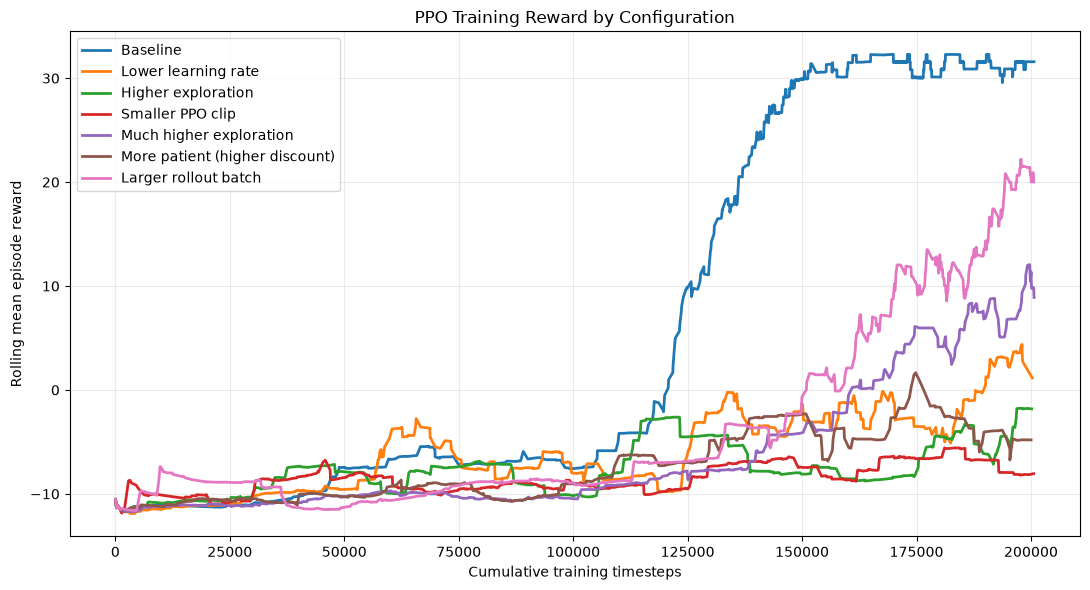

In [11]:
plt.figure(figsize=(11, 6))
plotted_training_runs = 0

for experiment in EXPERIMENTS_TO_RUN:
    monitor_path = RESULTS_DIRECTORY / f"{experiment['name']}_monitor.csv"
    if not monitor_path.exists():
        print("Training log not found:", monitor_path.name)
        continue

    monitor_df = pd.read_csv(monitor_path, comment="#")
    if monitor_df.empty:
        continue

    monitor_df["cumulative_timesteps"] = monitor_df["l"].cumsum()
    rolling_window = min(50, max(5, len(monitor_df) // 10))
    monitor_df["rolling_reward"] = monitor_df["r"].rolling(
        rolling_window,
        min_periods=1,
    ).mean()

    plt.plot(
        monitor_df["cumulative_timesteps"],
        monitor_df["rolling_reward"],
        linewidth=2,
        label=experiment["label"],
    )
    plotted_training_runs += 1

if plotted_training_runs == 0:
    plt.close()
    raise FileNotFoundError("No monitor CSV files are available; run the training queue first")

plt.title("PPO Training Reward by Configuration")
plt.xlabel("Cumulative training timesteps")
plt.ylabel("Rolling mean episode reward")
plt.grid(alpha=0.25)
plt.legend()
save_figure("training_reward_comparison.png")

### 10.2 Random baseline versus PPO metrics

The next figure uses three panels for mean reward, mean apples, and completion rate because these measures have different scales. Bar labels expose exact values, while a fixed completion-rate scale from zero to at least one prevents visual exaggeration. This is the main high-level comparison between untrained and learned behavior.


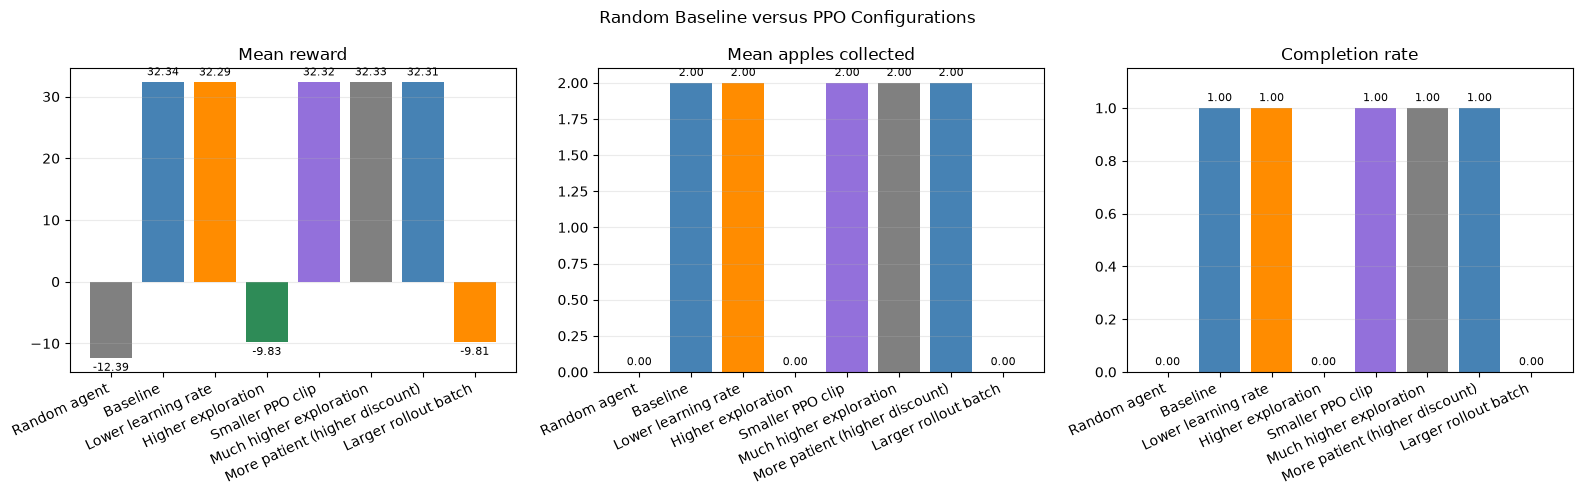

In [12]:
plot_comparison_df = comparison_df.set_index("label")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [
    ("mean_reward", "Mean reward"),
    ("mean_apples", "Mean apples collected"),
    ("completion_rate", "Completion rate"),
]
colors = ["gray", "steelblue", "darkorange", "seagreen", "mediumpurple"]

for axis, (column, label) in zip(axes, metrics):
    values = plot_comparison_df[column]
    bars = axis.bar(range(len(values)), values, color=colors[: len(values)])
    axis.set_title(label)
    axis.set_xticks(range(len(values)), plot_comparison_df.index, rotation=25, ha="right")
    axis.grid(axis="y", alpha=0.25)
    axis.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    if column == "completion_rate":
        axis.set_ylim(0, max(1.0, values.max() * 1.15))

fig.suptitle("Random Baseline versus PPO Configurations")
save_figure("all_policy_metric_comparison.png")

### 10.3 Terminal-outcome diagnosis

The next cell combines random and PPO terminal reasons, converts counts to within-policy proportions, and compares success, enemy collision, fall, and timeout rates. The graph explains *how* policies end episodes, which is more diagnostic than reward alone—for example, it separates failure caused by unsafe movement from failure caused by inaction.


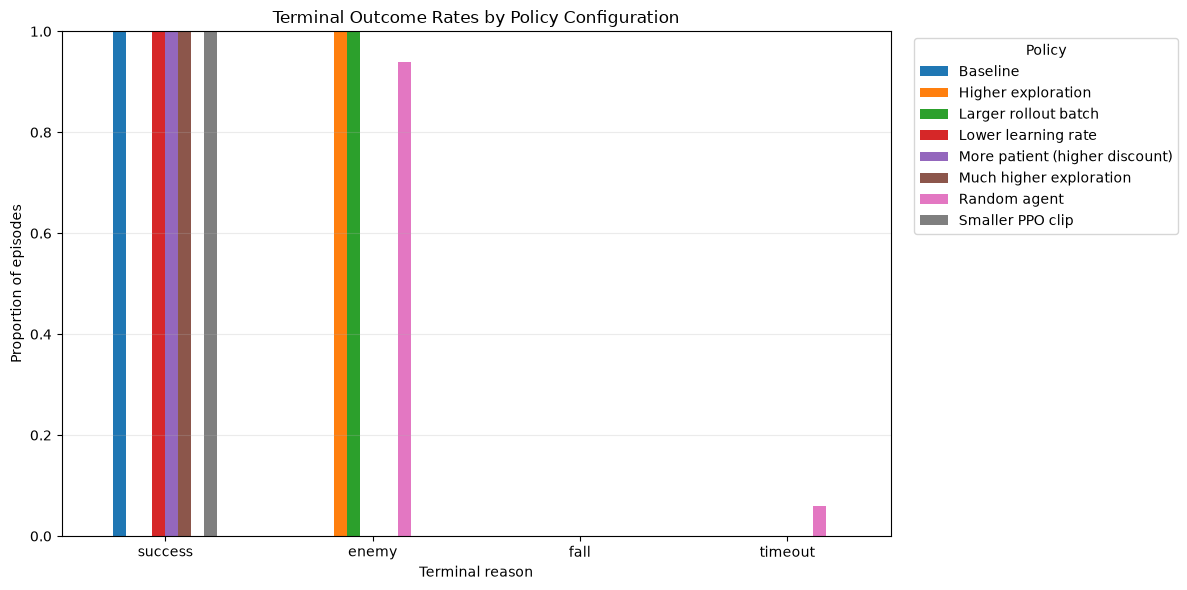

In [13]:
random_outcomes = random_results_df[["reason"]].copy()
random_outcomes["label"] = "Random agent"
ppo_outcomes = all_evaluation_df[["reason", "label"]].copy()
all_outcomes = pd.concat([random_outcomes, ppo_outcomes], ignore_index=True)

outcome_order = ["success", "enemy", "fall", "timeout"]
outcome_comparison = pd.crosstab(
    all_outcomes["reason"],
    all_outcomes["label"],
    normalize="columns",
).reindex(outcome_order).fillna(0.0)

outcome_comparison.plot(kind="bar", figsize=(12, 6))
plt.title("Terminal Outcome Rates by Policy Configuration")
plt.xlabel("Terminal reason")
plt.ylabel("Proportion of episodes")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Policy", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("all_terminal_outcomes.png")

### 10.4 Episode-level evaluation consistency

The next two-panel line plot shows deterministic reward and apples for every evaluation episode and configuration. Its purpose is to expose variation, repeated identical behavior, and isolated successes that an aggregate mean could hide. Empty configuration subsets are ignored.


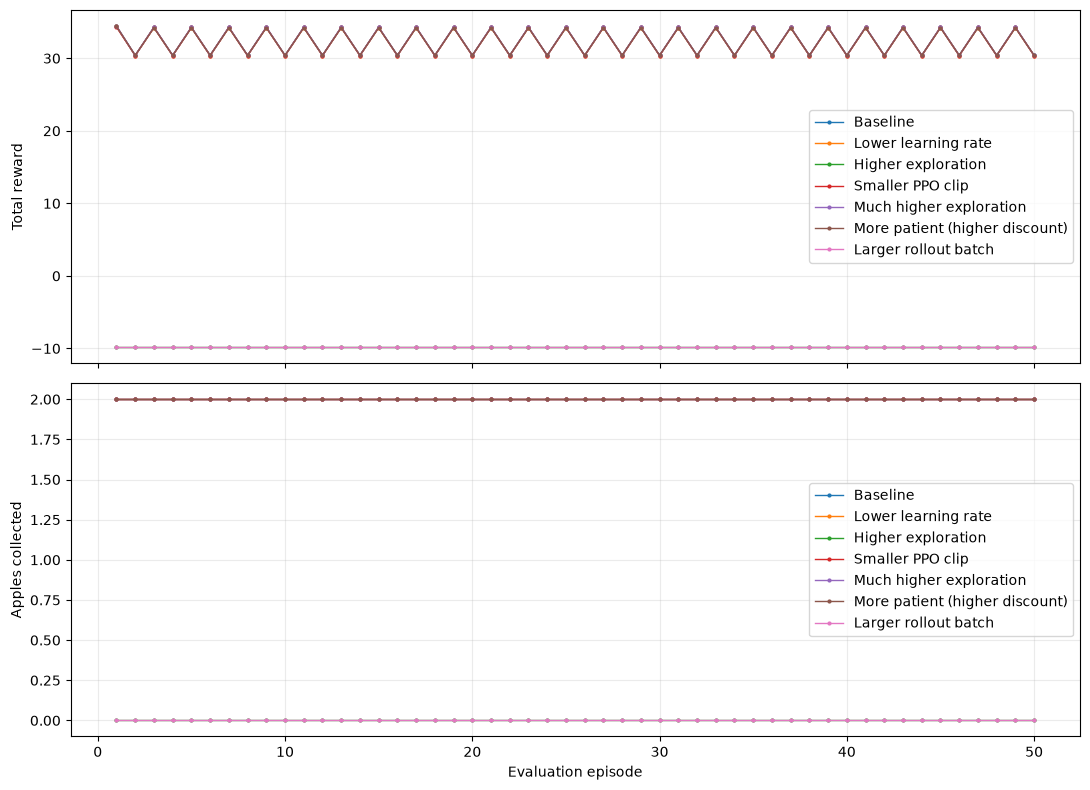

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for experiment in EXPERIMENTS_TO_RUN:
    subset = all_evaluation_df[all_evaluation_df["name"] == experiment["name"]]
    if subset.empty:
        continue
    axes[0].plot(
        subset["episode"],
        subset["reward"],
        marker="o",
        markersize=2,
        linewidth=1,
        label=experiment["label"],
    )
    axes[1].plot(
        subset["episode"],
        subset["apples_collected"],
        marker="o",
        markersize=2,
        linewidth=1,
        label=experiment["label"],
    )

axes[0].set_ylabel("Total reward")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].set_xlabel("Evaluation episode")
axes[1].set_ylabel("Apples collected")
axes[1].grid(alpha=0.25)
axes[1].legend()
save_figure("all_evaluation_consistency.png")

### 10.5 Apples-collected distribution

The histogram counts episodes ending with zero, one, or two apples for each configuration. Integer-centered bins avoid splitting an apple count across bars. This plot directly tests the common failure pattern in which the lower apple is collected but the upper apple and route waypoint are not mastered.


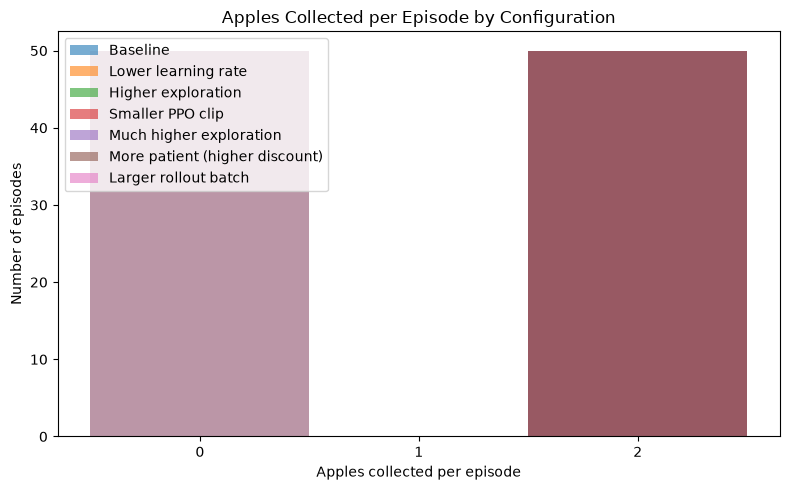

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
for experiment in EXPERIMENTS_TO_RUN:
    subset = all_evaluation_df[all_evaluation_df["name"] == experiment["name"]]
    # Bin edges are centered on 0, 1, 2 so each integer apple count gets its
    # own bar instead of being split across bin boundaries.
    ax.hist(
        subset["apples_collected"],
        bins=[-0.5, 0.5, 1.5, 2.5],
        alpha=0.6,
        label=experiment["label"],
    )
ax.set_xticks([0, 1, 2])
ax.set_xlabel("Apples collected per episode")
ax.set_ylabel("Number of episodes")
ax.set_title("Apples Collected per Episode by Configuration")
ax.legend()
save_figure("apples_collected_histogram.png")


## 11. Automatic result checks and model recommendation

The next cell prints cautious, task-oriented interpretations for every deterministic summary. It flags zero completion, zero reward variation, and improvements over the random control. It then recommends a configuration by completion rate first, mean apples second, and mean reward third. This ordering aligns model selection with the actual task rather than with shaped reward alone.


In [16]:
for _, result in experiment_summary_df.iterrows():
    print(f"\n{result['label']}:")
    if result["completion_rate"] == 0:
        print("• No successful completion; do not claim the task was solved.")
    else:
        print(f"• Completion rate: {result['completion_rate']:.1%}")
    if result["reward_std"] == 0:
        print("• Identical deterministic rewards; multiple training seeds are recommended.")
    if result["mean_reward"] > random_summary["mean_reward"]:
        print("• Mean reward improved relative to the random policy.")
    if result["mean_apples"] > random_summary["mean_apples"]:
        print("• More apples were collected than by the random policy.")

# Select lexicographically by task success, then partial progress, then reward.
# This prevents a short failing policy from winning merely because it avoids
# accumulating step penalties.
best_result = experiment_summary_df.sort_values(
    ["completion_rate", "mean_apples", "mean_reward"],
    ascending=False,
).iloc[0]
print(
    f"\nRecommended configuration: {best_result['label']} — "
    f"completion={best_result['completion_rate']:.1%}, "
    f"apples={best_result['mean_apples']:.2f}, "
    f"reward={best_result['mean_reward']:.3f}"
)


Baseline:
• Completion rate: 100.0%
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Lower learning rate:
• Completion rate: 100.0%
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Higher exploration:
• No successful completion; do not claim the task was solved.
• Identical deterministic rewards; multiple training seeds are recommended.
• Mean reward improved relative to the random policy.

Smaller PPO clip:
• Completion rate: 100.0%
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Much higher exploration:
• Completion rate: 100.0%
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

More patient (higher discount):
• Completion rate: 100.0%
• Mean reward improved relative to the random policy.
• More apples were collected than by the random poli

## 12. Best-policy trajectory heatmap

The next cell loads the recommended checkpoint and collects every player position from 30 stochastic episodes. A 2D visit-density map reveals which parts of the 1,280×720 level the policy explores. Godot's downward-positive y-axis is inverted for intuitive display. Sparse visits near the central-platform and upper-apple route provide spatial evidence for why a policy may stop after one apple.


Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org



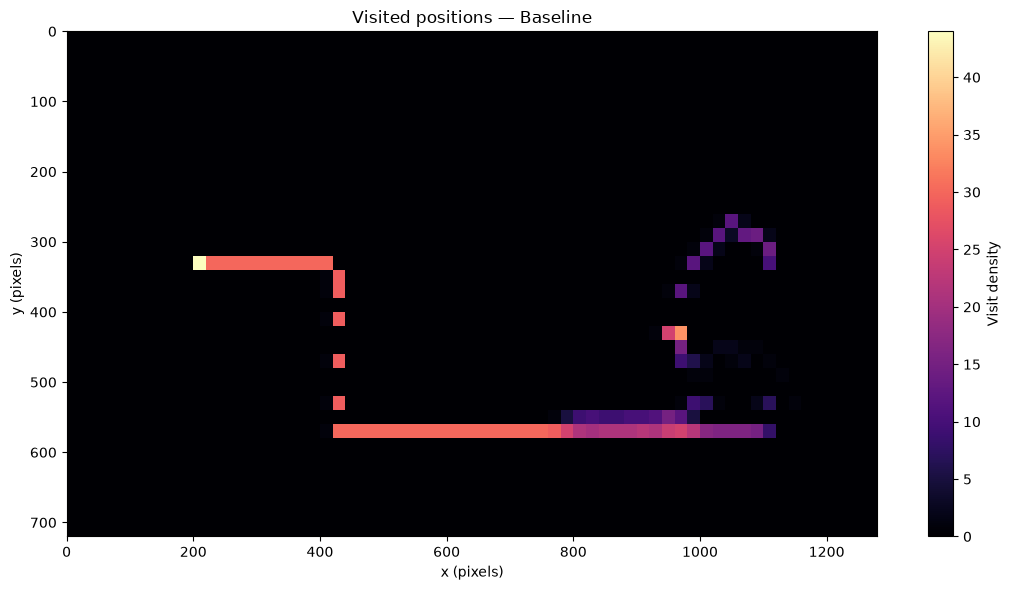

In [17]:
trajectory_env = AS1GodotEnv(headless=HEADLESS)
try:
    best_name = best_result["name"]  # from the automatic result checks above
    best_model = PPO.load(MODELS_DIRECTORY / f"as1_ppo_{best_name}_best")

    # run_episodes already returns per-step (x, y) positions as its second
    # value, so reuse it directly instead of a separate trajectory-collection
    # function. deterministic=False so the plot reflects the full range of
    # behavior the policy can produce, not just one fixed path.
    _, trajectory_df = run_episodes(
        trajectory_env, episodes=30, model=best_model, deterministic=False
    )
finally:
    trajectory_env.close()

trajectory_df.to_csv(RESULTS_DIRECTORY / f"{best_name}_trajectories.csv", index=False)

plt.figure(figsize=(11, 6))
plt.hist2d(
    trajectory_df["x"], trajectory_df["y"],
    bins=[64, 36],
    range=[[0, 1280], [0, 720]],
    cmap="magma",
)
plt.gca().invert_yaxis()  # Godot's y-axis increases downward
plt.colorbar(label="Visit density")
plt.title(f"Visited positions \u2014 {best_result['label']}")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
save_figure(f"{best_name}_position_heatmap.png")


## 13. Interpretation criteria and first-seed limitation

The initial comparison uses training seed `123`. Interpret configurations in this priority order:

1. Completion rate
2. Mean apples collected
3. Mean evaluation reward
4. Reward standard deviation
5. Mean episode length and terminal-outcome proportions

The notebook computes `best_result` automatically, so report values should be taken from the generated summaries rather than manually entered placeholders. The seven configurations form a controlled one-factor-at-a-time study, but one training seed cannot show whether an apparent advantage is robust to neural-network initialization and sampled experience. Sections 14.1–14.4 therefore repeat the experiment using three reproducibly generated additional seeds and aggregate across four seeds in total.

Training time depends strongly on hardware and rendering. Use the saved `training_seconds` metadata from the current runs instead of retaining an old wall-clock estimate.


## 14. Multi-seed validation

### 14.1 Define additional seeds

The next cell uses a fixed NumPy meta-seed (`1000`) to generate three additional integer seeds. Combining them with the original seed 123 produces four seeds per configuration. A reproducible seed matrix makes repeated grading or reruns select the same experimental conditions while still measuring sensitivity to independent initialization.


In [18]:
# Generate two additional seeds reproducibly. A fixed meta-seed (1000) means
# this exact list is identical every time the notebook is re-run.
SEED_META_RNG = np.random.default_rng(1000)
ADDITIONAL_SEEDS = [int(s) for s in SEED_META_RNG.integers(0, 1000, size=3)]
ALL_SEEDS = [SEED] + ADDITIONAL_SEEDS

print("Original training seed:", SEED)
print("Additional seeds:", ADDITIONAL_SEEDS)
print("Full seed matrix:", ALL_SEEDS)
print(f"Total training runs: {len(EXPERIMENTS_TO_RUN)} configs x {len(ALL_SEEDS)} seeds "
      f"= {len(EXPERIMENTS_TO_RUN) * len(ALL_SEEDS)} "
      f"({len(EXPERIMENTS_TO_RUN)} already trained, "
      f"{len(EXPERIMENTS_TO_RUN) * len(ADDITIONAL_SEEDS)} new)")

Original training seed: 123
Additional seeds: [203, 521, 848]
Full seed matrix: [123, 203, 521, 848]
Total training runs: 7 configs x 4 seeds = 28 (7 already trained, 21 new)


### 14.2 Train every configuration on the additional seeds

The next cell performs 21 new full training runs: seven configurations × three additional seeds. Before each run it reseeds Python/NumPy/PyTorch through Stable-Baselines3, launches a fresh monitored Godot environment, trains directly for the common 500,000-step budget, and saves the model and metadata using a seed-specific filename.

Completed seed-specific models can be skipped when resume mode is enabled. Unlike the initial queue, this loop does not run a separate smoke stage or save periodic checkpoints; its purpose is independent-seed replication of the final configurations.


In [19]:
import gc

seed_matrix_metadata = []

for seed in ADDITIONAL_SEEDS:
    for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
        name = experiment["name"]
        label = experiment["label"]
        run_name = f"{name}_seed{seed}"
        model_path = MODELS_DIRECTORY / f"as1_ppo_{run_name}"
        model_zip_path = model_path.with_suffix(".zip")
        monitor_path = RESULTS_DIRECTORY / f"{run_name}_monitor.csv"
        metadata_path = RESULTS_DIRECTORY / f"{run_name}_training_metadata.csv"
        resolved_config = {**BASE_PPO_CONFIG, **experiment["overrides"]}

        print(f"\n[seed {seed}, {queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label}")

        if SKIP_COMPLETED_MODELS and model_zip_path.exists():
            print("Completed model already exists; skipping training:", model_zip_path)
            if metadata_path.exists():
                seed_matrix_metadata.append(pd.read_csv(metadata_path).iloc[0].to_dict())
            continue

        # Reseed torch/numpy/random for this specific run so each of the 25
        # new runs is genuinely independent, not just re-using SEED's state.
        set_random_seed(seed)

        training_env = Monitor(
            AS1GodotEnv(headless=HEADLESS),
            filename=str(monitor_path),
            info_keywords=("reason", "apples_collected", "total_reward"),
        )
        training_start = time.perf_counter()

        try:
            model = PPO(
                policy="MlpPolicy",
                env=training_env,
                tensorboard_log=str(RESULTS_DIRECTORY / "tensorboard" / run_name),
                device="auto",
                seed=seed,
                verbose=1,
                **resolved_config,
            )
            model.learn(total_timesteps=TARGET_TOTAL_TIMESTEPS, progress_bar=True, tb_log_name=run_name)
            model.save(model_path)

            record = {
                "name": name,
                "label": label,
                "seed": seed,
                "timesteps": model.num_timesteps,
                "training_seconds": time.perf_counter() - training_start,
                **resolved_config,
            }
            pd.DataFrame([record]).to_csv(metadata_path, index=False)
            seed_matrix_metadata.append(record)
            print("Saved completed model:", model_zip_path)
        finally:
            training_env.close()
            if "model" in locals():
                del model
            gc.collect()

if seed_matrix_metadata:
    seed_matrix_metadata_df = pd.DataFrame(seed_matrix_metadata)
    seed_matrix_metadata_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_training_metadata.csv", index=False)
    display(seed_matrix_metadata_df)

print("\nMulti-seed training matrix finished.")


[seed 203, 1/7] Baseline
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/baseline_seed203/baseline_seed203_1


/Users/booxuan/miniconda3/envs/rl-ppo/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 121      |
|    ep_rew_mean     | -11.3    |
| time/              |          |
|    fps             | 2110     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 1024     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 219          |
|    ep_rew_mean          | -11.4        |
| time/                   |              |
|    fps                  | 1720         |
|    iterations           | 2            |
|    time_elapsed         | 1            |
|    total_timesteps      | 2048         |
| train/                  |              |
|    approx_kl            | 0.0096655805 |
|    clip_fraction        | 0.0459       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.79        |
|    explained_variance   | -0.0266      |
|    learning_r

Saved completed model: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/models/as1_ppo_baseline_seed203.zip

[seed 203, 2/7] Lower learning rate
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/results/tensorboard/low_lr_seed203/low_lr_seed203_1


/Users/booxuan/miniconda3/envs/rl-ppo/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 121      |
|    ep_rew_mean     | -11.3    |
| time/              |          |
|    fps             | 1706     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 1024     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 122         |
|    ep_rew_mean          | -11.3       |
| time/                   |             |
|    fps                  | 1462        |
|    iterations           | 2           |
|    time_elapsed         | 1           |
|    total_timesteps      | 2048        |
| train/                  |             |
|    approx_kl            | 0.002796084 |
|    clip_fraction        | 0           |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.79       |
|    explained_variance   | -0.0266     |
|    learning_rate        | 0.

... (56 outputs left out)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 213      |
|    ep_rew_mean     | -11.3    |
| time/              |          |
|    fps             | 2013     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 267         |
|    ep_rew_mean          | -11.2       |
| time/                   |             |
|    fps                  | 1603        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.013385836 |
|    clip_fraction        | 0.17        |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.78       |
|    explained_variance   | -0.0378     |
|    learning_rate        | 0.

Saved completed model: /Users/booxuan/Documents/UCCD2063-Artificial-Intelligence-Techniques-RL-Godot/GodotGameEngineScene/as_1/models/as1_ppo_larger_rollout_seed848.zip


,name,label,seed,timesteps,training_seconds,learning_rate,n_steps,batch_size,n_epochs,gamma,gae_lambda,clip_range,ent_coef
0,baseline,Baseline,203,200704,142.696184,0.0003,1024,64,10,0.990,0.95,0.2,0.01
1,low_lr,Lower learning rate,203,200704,146.769599,0.0001,1024,64,10,0.990,0.95,0.2,0.01
2,high_entropy,Higher exploration,203,200704,136.523820,0.0003,1024,64,10,0.990,0.95,0.2,0.02
3,low_clip,Smaller PPO clip,203,200704,136.100218,0.0003,1024,64,10,0.990,0.95,0.1,0.01
4,very_high_entropy,Much higher exploration,203,200704,156.457829,0.0003,1024,64,10,0.990,0.95,0.2,0.05
5,high_gamma,More patient (higher discount),203,200704,151.113157,0.0003,1024,64,10,0.995,0.95,0.2,0.01
6,larger_rollout,Larger rollout batch,203,200704,158.459578,0.0003,2048,64,10,0.990,0.95,0.2,0.01
7,baseline,Baseline,521,200704,138.339130,0.0003,1024,64,10,0.990,0.95,0.2,0.01
8,low_lr,Lower learning rate,521,200704,144.408600,0.0001,1024,64,10,0.990,0.95,0.2,0.01
9,high_entropy,Higher exploration,521,200704,148.435668,0.0003,1024,64,10,0.990,0.95,0.2,0.02



Multi-seed training matrix finished.


### 14.3 Evaluate every configuration–seed pair

The next cell discovers the original and seed-specific final model files, runs the common 50-episode deterministic protocol for each available pair, and saves one summary row per configuration and seed. Missing files are reported and skipped so partial matrices can still be inspected.

For seed 123 this stage loads the final `as1_ppo_<name>.zip` model, whereas Section 8 prefers the checkpoint-screened `*_best.zip`. Therefore the seed-matrix comparison is a final-model comparison and should not be mixed directly with Section 8's best-checkpoint statistics.


In [20]:
seed_matrix_results = []

for seed in ALL_SEEDS:
    for experiment in EXPERIMENTS_TO_RUN:
        name = experiment["name"]
        label = experiment["label"]
        run_name = name if seed == SEED else f"{name}_seed{seed}"
        model_zip_path = MODELS_DIRECTORY / f"as1_ppo_{run_name}.zip"

        if not model_zip_path.exists():
            print(f"Skipping evaluation; model not found: {model_zip_path}")
            continue

        print(f"Evaluating {label} (seed {seed})")
        model = PPO.load(model_zip_path.with_suffix(""))
        evaluation_env = AS1GodotEnv(headless=HEADLESS)

        try:
            result_df, _ = run_episodes(
                evaluation_env,
                FINAL_EVALUATION_EPISODES,
                model=model,
                deterministic=True,
            )
        finally:
            evaluation_env.close()

        summary = summarize_results(result_df)
        summary["name"] = name
        summary["label"] = label
        summary["seed"] = seed
        seed_matrix_results.append(summary)

        del model
        gc.collect()

seed_matrix_results_df = pd.DataFrame(seed_matrix_results)
seed_matrix_results_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_evaluation_results.csv", index=False)
display(seed_matrix_results_df[
    ["label", "seed", "mean_reward", "mean_apples", "completion_rate"]
].round(3))

Evaluating Baseline (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Lower learning rate (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Higher exploration (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Smaller PPO clip (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Much higher exploration (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating More patient (higher discount) (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Larger rollout batch (seed 123)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Baseline (seed 203)
Godot Engine v4.6.3.stable.official.7d41c59c4 - https://godotengine.org

Evaluating Lower learning rate (seed 203)
Godot Engine v4.6.3.stable.official.7d41c59c4 - 

,label,seed,mean_reward,mean_apples,completion_rate
0,Baseline,123,32.294,2.00,1.00
1,Lower learning rate,123,-18.000,0.00,0.00
2,Higher exploration,123,-9.802,0.00,0.00
3,Smaller PPO clip,123,-18.000,0.00,0.00
4,Much higher exploration,123,-8.100,1.00,0.00
5,More patient (higher discount),123,-12.383,1.00,0.00
6,Larger rollout batch,123,18.828,1.68,0.68
7,Baseline,203,-10.379,0.00,0.00
8,Lower learning rate,203,-12.240,1.00,0.00
9,Higher exploration,203,32.340,2.00,1.00


### 14.4 Aggregate mean ± standard deviation across seeds

The next cell groups seed-level summaries by configuration and calculates the mean and sample standard deviation of completion rate, apples, and reward, plus the number of seeds actually evaluated. It exports `seed_matrix_summary.csv` and plots mean completion with seed-to-seed error bars. With a complete run, each estimate is based on four seeds; always verify `seeds_evaluated` before citing the result.


,name,label,completion_rate_mean,completion_rate_std,mean_apples_mean,mean_apples_std,mean_reward_mean,mean_reward_std,seeds_evaluated
0,baseline,Baseline,0.250,0.500,0.875,0.854,-0.534,21.904,4
1,high_entropy,Higher exploration,0.250,0.500,0.750,0.957,0.155,21.483,4
2,high_gamma,More patient (higher discount),0.000,0.000,0.750,0.500,-10.832,2.124,4
3,larger_rollout,Larger rollout batch,0.420,0.502,1.420,0.502,8.839,20.114,4
4,low_clip,Smaller PPO clip,0.250,0.500,0.750,0.957,-1.035,22.619,4
5,low_lr,Lower learning rate,0.000,0.000,0.500,0.577,-13.042,3.488,4
6,very_high_entropy,Much higher exploration,0.125,0.250,0.875,0.629,-5.760,14.212,4


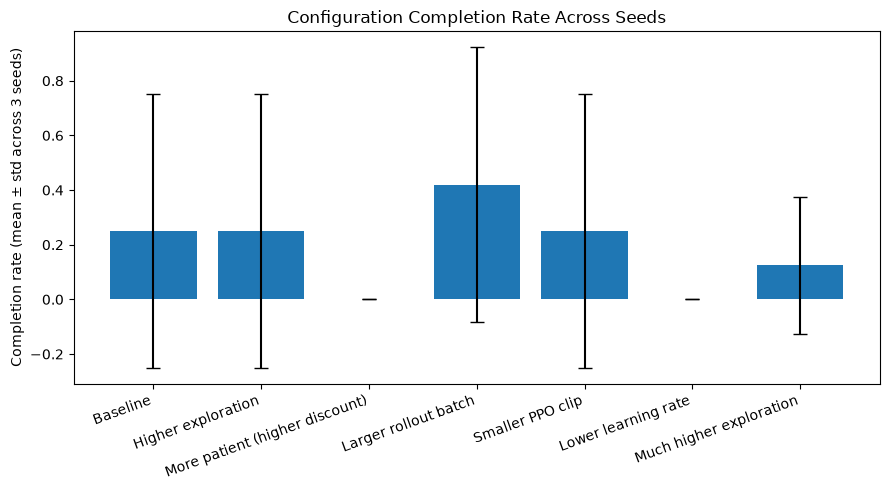

In [21]:
seed_matrix_summary_df = (
    seed_matrix_results_df
    .groupby(["name", "label"])
    .agg(
        completion_rate_mean=("completion_rate", "mean"),
        completion_rate_std=("completion_rate", "std"),
        mean_apples_mean=("mean_apples", "mean"),
        mean_apples_std=("mean_apples", "std"),
        mean_reward_mean=("mean_reward", "mean"),
        mean_reward_std=("mean_reward", "std"),
        seeds_evaluated=("seed", "count"),
    )
    .reset_index()
)
seed_matrix_summary_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_summary.csv", index=False)
display(seed_matrix_summary_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
x_positions = np.arange(len(seed_matrix_summary_df))
ax.bar(
    x_positions,
    seed_matrix_summary_df["completion_rate_mean"],
    yerr=seed_matrix_summary_df["completion_rate_std"],
    capsize=5,
)
ax.set_xticks(x_positions)
ax.set_xticklabels(seed_matrix_summary_df["label"], rotation=20, ha="right")
ax.set_ylabel("Completion rate (mean ± std across 3 seeds)")
ax.set_title("Configuration Completion Rate Across Seeds")
save_figure("seed_matrix_completion_rate.png")

## 15. Assignment report material checklist

### Methodology evidence

- Environment screenshot and task description
- Observation, action, reward, termination, and truncation definitions
- Python–WebSocket–Godot interaction explanation
- PPO algorithm and policy-network explanation
- Seven-configuration controlled hyperparameter table
- Training budget, software/hardware versions, and seed protocol
- Checkpoint-screening and deterministic/stochastic evaluation procedures

### Results evidence

- Training learning-curve comparison
- Random-versus-PPO metric table and graph
- Terminal-outcome proportions
- Episode-level consistency and apples distribution
- Best-policy trajectory heatmap
- Four-seed mean ± standard deviation table when the matrix is complete
- Raw CSV evidence and measured training times

### Discussion evidence

- Select the best policy using completion and apples before reward
- Explain dominant failure modes and route coverage
- Discuss deterministic versus stochastic behavior
- Relate each result to the single hyperparameter changed
- State missing runs, zero completion, or incomplete seed matrices honestly

Console screenshots are optional appendix material; they do not replace saved metrics, plots, and interpretation.


## 16. Operations review and redundancy audit

The code review found the following redundant or duplicated operations:

1. **Inactive JSON configuration loader (cell 14):** the entire block is inside a triple-quoted string, so it performs no operation. It duplicates the active baseline/configuration construction in cell 15 and can be removed after any useful history is moved to version control.
2. **Unused configuration path:** `CONFIG_DIRECTORY` and its printed value are only referenced by that inactive loader; there is currently no active `ppo_configs/` workflow.
3. **Duplicate random-action seeding:** `random_env.action_space.seed(SEED)` is repeated by the first `run_episodes(..., seed=SEED)` reset because `AS1GodotEnv.reset` also seeds the action space.
4. **Repeated import:** `import gc` appears before both training loops. Python caches imports, so the second import is harmless but unnecessary.
5. **Unused checkpoint dictionary:** `best_checkpoint_paths` is populated during screening but never read later; later cells reconstruct model paths from filenames.
6. **Duplicated training-loop structure:** the initial and multi-seed queues repeat model/environment/metadata setup. Their behavior is not identical, so both experiments are meaningful, but a shared training helper would reduce maintenance drift.
7. **Repeated environment validation:** `check_env` appears in both this notebook and `test_environment.py`. Keeping both is useful for independent execution, but running both every time duplicates the basic interface check.
8. **Unused Godot signal:** `main.gd` emits `step_finished`, but the current bridge directly awaits `agent_step` and no project code connects to the signal. The signal emission is therefore presently redundant.

Expensive operations that are **not inherently redundant** include deterministic plus stochastic evaluation, periodic checkpoint screening, and multi-seed retraining: each answers a different reliability question. They can be reduced for development runs, but removing them from final experiments would weaken the evidence.

### Non-redundancy issues discovered during review

- `test_environment.py` still comments and asserts the earlier −30 terminal penalty and +15 apple reward. The active `main.gd` values are −10 and +5, so enemy/fall assertions can fail even when the current environment is correct.
- Some code comments and a plot-axis label still describe four JSON configurations, two additional seeds, 25 new runs, or three-seed aggregation. Active code uses seven inline configurations, three additional seeds, 21 new runs, and four total seeds.
- Section 8 evaluates checkpoint-selected best models, while the multi-seed matrix evaluates final models. Use one checkpoint policy consistently if those result sets must be compared directly.
